
# Experiment 01 — YOLO11n Baseline Training

## Research Objective
Establish a reproducible baseline for bird detection
using YOLO11n on the Beach Bird Detection Dataset.

## Experimental Design
- Model: YOLO11n (pretrained)
- Dataset: Beach Bird Detection Dataset v1.0
- Task: Single-class bird detection
- Hardware: Apple M4 Pro (MPS)

## Evaluation Metrics
- Training and Validation Loss
- Precision and Recall
- mAP@0.5 and mAP@0.5:0.95
- Training Time and Inference Latency

## Research Questions
1. How effectively can YOLO detect birds of different sizes?
2. How does detection performance vary across visual conditions?
3. What are the primary causes of false positives and false negatives?


In [2]:

from pathlib import Path
import sys
import platform
import yaml
import torch
import ultralytics

# 1. Locate project root
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

assert (ROOT / "configs/yolo_baseline.yaml").exists(), \
    "Training configuration not found!"

# 2. Load YAML configuration
CONFIG_PATH = ROOT / "configs/yolo_baseline.yaml"

with open(CONFIG_PATH, "r") as f:
    config = yaml.safe_load(f)

# 3. Display environment information
print("=== Environment ===")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Platform:", platform.platform())
print("MPS available:", torch.backends.mps.is_available())

# 4. Display training configuration
print("\n=== Training Configuration ===")

for key, value in config.items():
    print(f"{key}: {value}")

# 5. Verify dataset
DATASET_YAML = ROOT / config["data"]

assert DATASET_YAML.exists(), "Dataset YAML not found!"

print("\nDataset configuration verified.")


=== Environment ===
Python: 3.11.16
PyTorch: 2.15.0
Ultralytics: 8.4.199
Platform: macOS-15.1-arm64-arm-64bit
MPS available: True

=== Training Configuration ===
model: yolo11n.pt
data: data/beach_bird.yaml
epochs: 50
imgsz: 640
batch: 4
device: mps
workers: 0
seed: 42
deterministic: False
patience: 15
plots: True
save: True
project: runs/train
name: yolo11n_baseline_v1
exist_ok: False

Dataset configuration verified.


In [3]:

import pandas as pd
from ultralytics import YOLO

# Load pretrained model
weight_path = ROOT / config["model"]

model = YOLO(
    str(weight_path) if weight_path.exists()
    else config["model"]
)

# Model summary
model.info(imgsz=config["imgsz"])

# Inspect each model block
layers = []

for layer in model.model.model:
    idx = layer.i

    if idx <= 10:
        stage = "Backbone"
    elif idx == len(model.model.model) - 1:
        stage = "Detection Head"
    else:
        stage = "Neck"

    layers.append({
        "Index": idx,
        "Stage": stage,
        "From": str(layer.f),
        "Module": type(layer).__name__,
        "Parameters": sum(
            p.numel() for p in layer.parameters()
        ),
    })

architecture_df = pd.DataFrame(layers)
display(architecture_df)

print("Pretrained classes:", model.model.model[-1].nc)


YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


,Index,Stage,From,Module,Parameters
0,0,Backbone,-1,Conv,464
1,1,Backbone,-1,Conv,4672
2,2,Backbone,-1,C3k2,6640
3,3,Backbone,-1,Conv,36992
4,4,Backbone,-1,C3k2,26080
5,5,Backbone,-1,Conv,147712
6,6,Backbone,-1,C3k2,87040
7,7,Backbone,-1,Conv,295424
8,8,Backbone,-1,C3k2,346112
9,9,Backbone,-1,SPPF,164608


Pretrained classes: 80


In [4]:

from ultralytics import YOLO
from datetime import datetime
from pathlib import Path
import time
import json
import torch
import ultralytics

# 1. Prepare configuration
train_config = config.copy()

model_name = train_config.pop("model")

# Use absolute paths
train_config["data"] = str(ROOT / train_config["data"])
train_config["project"] = str(ROOT / train_config["project"])

# 2. Load pretrained model
train_model = YOLO(model_name)

# 3. Record start time
started_at = datetime.now().astimezone().isoformat()
start = time.perf_counter()

# 4. Start baseline training
train_model.train(**train_config)

# 5. Record elapsed time
elapsed = time.perf_counter() - start

run_dir = Path(train_model.trainer.save_dir)

# 6. Save experiment metadata
metadata = {
    "experiment": "YOLO11n Baseline",
    "started_at": started_at,
    "training_wall_time_seconds": round(elapsed, 2),
    "pytorch_version": torch.__version__,
    "ultralytics_version": ultralytics.__version__,
    "configuration": train_config,
    "model": model_name,
}

with open(run_dir / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\n===== Training Completed =====")
print("Training time:", round(elapsed, 2), "seconds")
print("Results directory:", run_dir)


New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird.yaml, degrees=0.0, deterministic=False, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train,

In [5]:

import pandas as pd
from pathlib import Path

run_dir = ROOT / "runs/train/yolo11n_baseline_v1"

df = pd.read_csv(run_dir / "results.csv")
df.columns = df.columns.str.strip()

# Select best validation epoch
best_idx = df["metrics/mAP50-95(B)"].idxmax()
best = df.loc[best_idx]

summary = pd.DataFrame([{
    "Model": "YOLO11n",
    "Best Epoch": int(best["epoch"]),
    "Precision": best["metrics/precision(B)"],
    "Recall": best["metrics/recall(B)"],
    "mAP50": best["metrics/mAP50(B)"],
    "mAP50-95": best["metrics/mAP50-95(B)"],
    "CSV Time (s)": df["time"].iloc[-1]
}])

display(summary)

# Export for future model comparison
summary.to_csv(run_dir / "baseline_summary.csv", index=False)


,Model,Best Epoch,Precision,Recall,mAP50,mAP50-95,CSV Time (s)
0,YOLO11n,50,0.86713,0.79219,0.86762,0.47108,2147.16


In [6]:

from ultralytics import YOLO

# Load best trained checkpoint
best_model = YOLO(
    str(ROOT / "runs/train/yolo11n_baseline_v1/weights/best.pt")
)

# Re-evaluate with a higher confidence threshold
metrics = best_model.val(
    data=str(ROOT / "data/beach_bird.yaml"),
    split="val",
    imgsz=640,
    batch=4,
    device="mps",
    workers=0,
    conf=0.25,
    iou=0.7,
    plots=True,
    project=str(ROOT / "runs/evaluation"),
    name="yolo11n_conf025",
    exist_ok=False,
)

# Inspect confusion matrix
cm = metrics.confusion_matrix.matrix

tp = cm[0, 0]
fp = cm[0, 1]
fn = cm[1, 0]

print("True Positives:", int(tp))
print("False Positives:", int(fp))
print("False Negatives:", int(fn))

print("Precision:", tp / (tp + fp) if tp + fp else 0)
print("Recall:", tp / (tp + fn) if tp + fn else 0)


Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 427.4±201.0 MB/s, size: 118.9 KB)
val: Scanning /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/val.cache... 291 images, 33 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 291/291 152.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 23.8it/s 3.1s0.0s
                   all        291       1843      0.866      0.793      0.811      0.443
Speed: 0.3ms preprocess, 2.0ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /Users/luzhang/COMP9517/comp9517-bird-detection/runs/evaluation/yolo11n_conf025
True Positives: 1595
False Positives: 451
False Negatives: 248
Precision: 0.7795698924731183
Recall: 0.8654367878459034


In [7]:

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle
from ultralytics import YOLO

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from bird_detection.evaluation.error_analysis import evaluate_image

DATASET = ROOT / "data/beach_bird/Beach Bird Detection Dataset v1.0"

model = YOLO(
    str(ROOT / "runs/train/yolo11n_baseline_v1/weights/best.pt")
)

# Inference on the validation set only
predictions = model.predict(
    source=str(DATASET / "images/val"),
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device="mps",
    batch=4,
    stream=True,
    verbose=False
)

records = []

for result in predictions:
    label_path = DATASET / "labels/val" / (
        Path(result.path).stem + ".txt"
    )

    record = evaluate_image(result, label_path)
    records.append(record)

# Create image-level evaluation table
df = pd.DataFrame([
    {
        "image": Path(r["image"]).name,
        "gt_count": r["gt_count"],
        "TP": r["tp"],
        "FP": r["fp"],
        "FN": r["fn"],
        "F1": r["f1"]
    }
    for r in records
])

# Save for future analysis
output_dir = ROOT / "runs/evaluation/yolo11n_failure_analysis"
output_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(output_dir / "per_image_scores.csv", index=False)

# Rank images containing at least 3 annotated birds
worst = sorted(
    [r for r in records if r["gt_count"] >= 3],
    key=lambda r: (r["f1"], -r["fn"], -r["fp"])
)[:5]

display(df[df["gt_count"] >= 3].sort_values("F1").head(5))


,image,gt_count,TP,FP,FN,F1
49,beach_bird_1419.jpg,5,0,3,5,0.000000
127,beach_bird_1497.jpg,4,0,4,4,0.000000
128,beach_bird_1498.jpg,4,0,6,4,0.000000
52,beach_bird_1422.jpg,7,1,5,6,0.153846
51,beach_bird_1421.jpg,5,1,6,4,0.166667


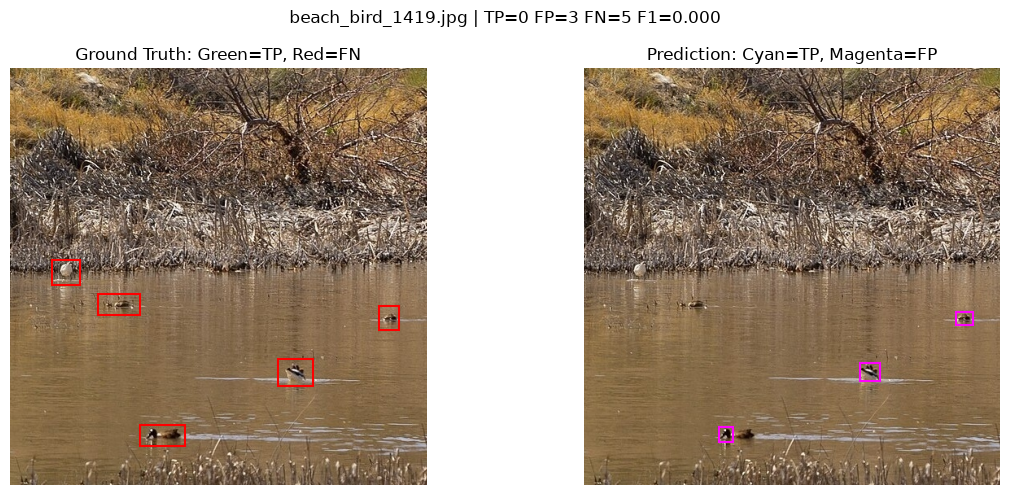

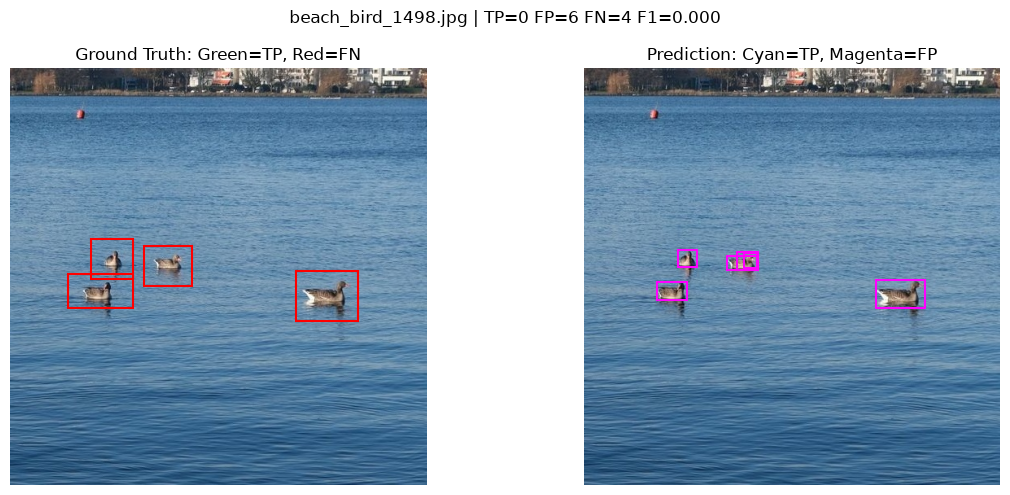

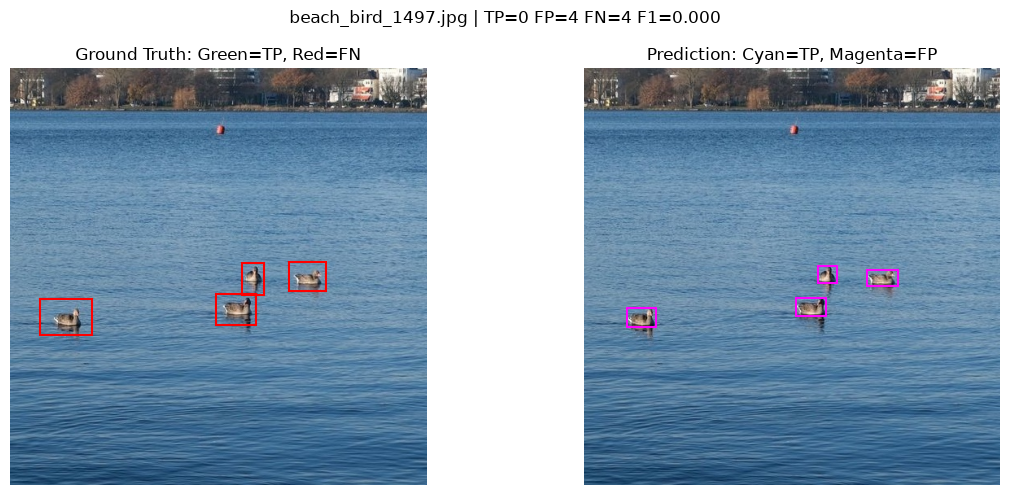

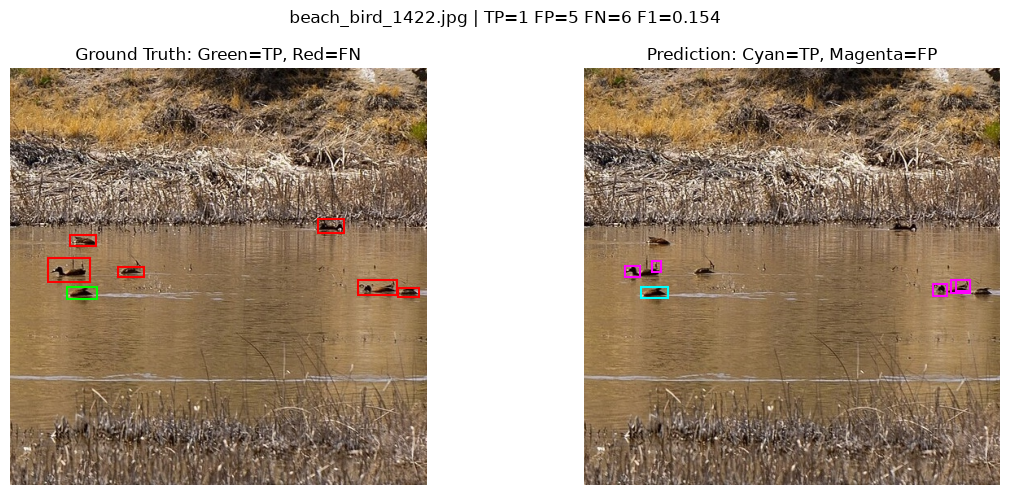

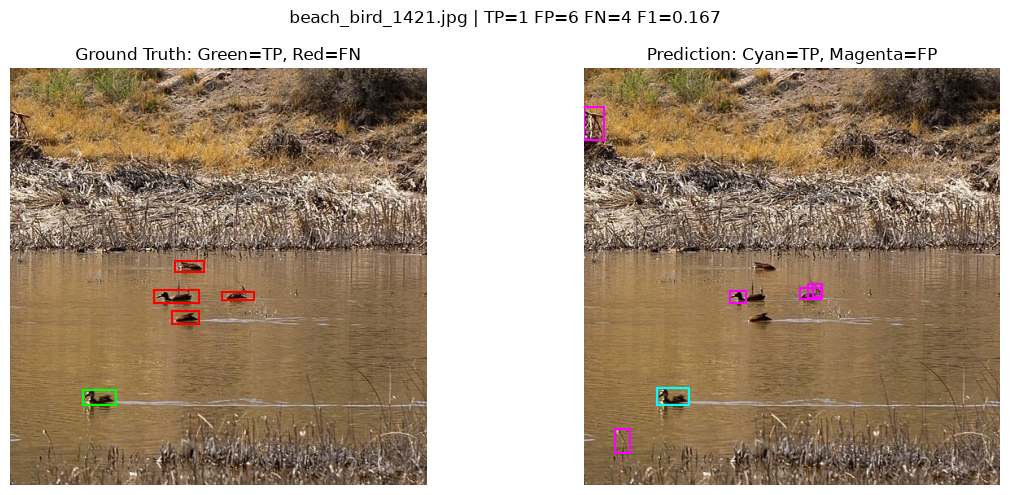

In [8]:

for r in worst:
    with Image.open(r["image"]) as image:
        img = image.convert("RGB").copy()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax in axes:
        ax.imshow(img)
        ax.axis("off")

    # Ground Truth: green = matched, red = missed
    for i, box in enumerate(r["gt_boxes"]):
        x1, y1, x2, y2 = box
        color = "lime" if i in r["matched_gt"] else "red"

        axes[0].add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor=color, linewidth=1.5
        ))

    # Prediction: cyan = matched, magenta = false positive
    for j, box in enumerate(r["pred_boxes"]):
        x1, y1, x2, y2 = box
        color = "cyan" if j in r["matched_pred"] else "magenta"

        axes[1].add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor=color, linewidth=1.5
        ))

    axes[0].set_title("Ground Truth: Green=TP, Red=FN")
    axes[1].set_title("Prediction: Cyan=TP, Magenta=FP")

    fig.suptitle(
        f"{Path(r['image']).name} | "
        f"TP={r['tp']} FP={r['fp']} FN={r['fn']} "
        f"F1={r['f1']:.3f}"
    )

    plt.tight_layout()
    plt.show()


In [1]:

from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

for path in sorted((ROOT / "runs/train").glob("*")):
    if "yolo" not in path.name.lower():
        continue

    best = path / "weights/best.pt"
    csv = path / "results.csv"

    if best.exists() and csv.exists():
        df = pd.read_csv(csv)
        df.columns = df.columns.str.strip()

        print(
            path.name,
            "| Epochs:", len(df),
            "| Best mAP50:", round(
                df["metrics/mAP50(B)"].max(), 4
            ),
            "| Best mAP50-95:", round(
                df["metrics/mAP50-95(B)"].max(), 4
            )
        )
        print("Checkpoint:", best)
        print()


yolo11n_baseline_v1 | Epochs: 50 | Best mAP50: 0.8676 | Best mAP50-95: 0.4711
Checkpoint: /Users/luzhang/COMP9517/comp9517-bird-detection/runs/train/yolo11n_baseline_v1/weights/best.pt

yolo11n_smoke | Epochs: 1 | Best mAP50: 0.006 | Best mAP50-95: 0.0013
Checkpoint: /Users/luzhang/COMP9517/comp9517-bird-detection/runs/train/yolo11n_smoke/weights/best.pt



In [2]:

from pathlib import Path
from ultralytics import YOLO
import json

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Final YOLO checkpoint
best_path = (
    ROOT / "runs/train/yolo11n_baseline_v1"
    / "weights/best.pt"
)

assert best_path.is_file(), "Checkpoint not found"

model = YOLO(str(best_path))

# Evaluate on the held-out test set
metrics = model.val(
    data=str(ROOT / "data/beach_bird.yaml"),
    split="test",
    imgsz=640,
    batch=4,
    device="mps",
    workers=0,
    augment=False,
    plots=True,
    project=str(ROOT / "runs/eval"),
    name="yolo11n_test_final",
    exist_ok=False,
)

# Save results
results = {
    "model": "YOLO11n Baseline",
    "checkpoint": str(best_path),
    "split": "test",
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
}

output_dir = Path(metrics.save_dir)
(output_dir / "test_metrics.json").write_text(
    json.dumps(results, indent=2)
)

print("\n===== YOLO FINAL TEST =====")
for key, value in results.items():
    print(f"{key}: {value}")

print("Saved to:", output_dir)


Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 338.4±186.8 MB/s, size: 127.3 KB)
val: Scanning /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/test.cache... 240 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 240/240 251.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 17.1it/s 3.5s0.1s
                   all        240       1518      0.872      0.782      0.871      0.484
Speed: 0.3ms preprocess, 2.8ms inference, 0.0ms loss, 6.1ms postprocess per image
Results saved to /Users/luzhang/COMP9517/comp9517-bird-detection/runs/eval/yolo11n_test_final

===== YOLO FINAL TEST =====
model: YOLO11n Baseline
checkpoint: /Users/luzhang/COMP9517/comp9517-bird-detection/runs/train/yolo11n_baseline_v1/weights/b